<a href="https://colab.research.google.com/github/Nandhish130/DL-CAT-2/blob/main/IMDb_Sentiment_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive (2).zip


In [ ]:

import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/imdb_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))


Dataset extracted successfully!
['train.csv', 'test.csv']


In [ ]:

import pandas as pd

df = pd.read_csv("/content/imdb_data/train.csv")

print("Dataset size:", df.shape)
print("Columns:", df.columns.tolist())
print("\nSentiment counts:")
print(df["sentiment"].value_counts())


Dataset size: (25000, 2)
Columns: ['text', 'sentiment']

Sentiment counts:
sentiment
neg    12500
pos    12500
Name: count, dtype: int64


In [ ]:

df = df[["text", "sentiment"]].dropna()
df["sentiment"] = df["sentiment"].str.lower().str.strip()
df = df[df["sentiment"].isin(["neg", "pos"])]
df = df.drop_duplicates(subset="text")

parts = []

for label in ["neg", "pos"]:
    group = df[df["sentiment"] == label]
    parts.append(
        group.sample(n=min(2500, len(group)), random_state=42)
    )

data = pd.concat(parts).sample(frac=1, random_state=42)
data = data.reset_index(drop=True)

print("Selected reviews:", len(data))
print(data["sentiment"].value_counts())


Selected reviews: 5000
sentiment
neg    2500
pos    2500
Name: count, dtype: int64


In [ ]:

import re
import numpy as np

def clean_text(text):
    text = re.sub(r"<br\s*/?>", " ", str(text), flags=re.I)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-zA-Z']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.lower().strip()

data["text"] = data["text"].apply(clean_text)

# Negative = 0, Positive = 1
data["label"] = data["sentiment"].map({"neg": 0, "pos": 1})

print(data[["text", "sentiment", "label"]].head())


                                                text sentiment  label
0  just as its a mad mad mad mad world is at the ...       neg      0
1  i gave this movie such a high mark because it ...       pos      1
2  i first saw this movie on television some year...       pos      1
3  okay first of all i didn't sit down to watch t...       neg      0
4  this movie is lame and not funny at all the pl...       neg      0


In [ ]:

from sklearn.model_selection import train_test_split

X = data["text"].values
y = data["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

print("Training set:", len(X_train))
print("Validation set:", len(X_val))
print("Testing set:", len(X_test))


Training set: 3500
Validation set: 750
Testing set: 750


In [ ]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 15000
MAX_LEN = 200

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)
X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)


Training shape: (3500, 200)
Validation shape: (750, 200)
Testing shape: (750, 200)


In [ ]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:

from tensorflow.keras.callbacks import EarlyStopping

model.build(input_shape=(None, MAX_LEN))

model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=6,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       960,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,985,413 (11.39 MB)

 Trainable params: 995,137 (3.80 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,990,276 (7.59 MB)

Epoch 1/6
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 197ms/step - accuracy: 0.9577 - loss: 0.1297 - val_accuracy: 0.8000 - val_loss: 0.6073
Epoch 2/6
55/55 ━━━━━━━━━━━━━━━━━━━━ 9s 166ms/step - accuracy: 0.9674 - loss: 0.1105 - val_accuracy: 0.7667 - val_loss: 0.6287
Epoch 3/6
55/55 ━━━━━━━━━━━━━━━━━━━━ 10s 184ms/step - accuracy: 0.9697 - loss: 0.0900 - val_accuracy: 0.7507 - val_loss: 0.6741


In [16]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

test_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (test_prob >= 0.5).astype(int)

print("Test Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Test Precision:", round(precision_score(y_test, y_pred), 4))
print("Test Recall   :", round(recall_score(y_test, y_pred), 4))
print("Test F1-score :", round(f1_score(y_test, y_pred), 4))

Test Accuracy : 0.796
Test Precision: 0.7581
Test Recall   : 0.8693
Test F1-score : 0.8099


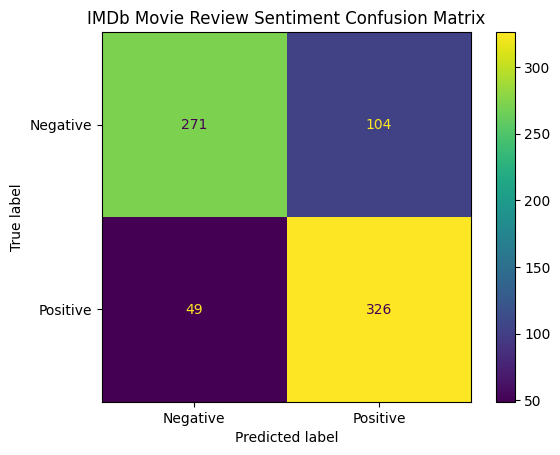

In [18]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(values_format="d")
plt.title("IMDb Movie Review Sentiment Confusion Matrix")
plt.show()


In [19]:

unseen_reviews = [
    "This movie was fantastic and the acting was brilliant.",
    "The film was boring and the story was terrible.",
    "I really enjoyed this wonderful and entertaining movie.",
    "The worst movie I have ever watched. A complete waste of time.",
    "The story was interesting and the actors gave excellent performances."
]

clean_reviews = [clean_text(r) for r in unseen_reviews]
new_sequences = tokenizer.texts_to_sequences(clean_reviews)

new_padded = pad_sequences(
    new_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

probabilities = model.predict(new_padded, verbose=0).ravel()

for i, (review, prob) in enumerate(
    zip(unseen_reviews, probabilities), start=1
):
    sentiment = "Positive" if prob >= 0.5 else "Negative"
    print(f"\nReview {i}: {review}")
    print(f"Predicted Sentiment: {sentiment}")



Review 1: This movie was fantastic and the acting was brilliant.
Predicted Sentiment: Positive

Review 2: The film was boring and the story was terrible.
Predicted Sentiment: Negative

Review 3: I really enjoyed this wonderful and entertaining movie.
Predicted Sentiment: Positive

Review 4: The worst movie I have ever watched. A complete waste of time.
Predicted Sentiment: Negative

Review 5: The story was interesting and the actors gave excellent performances.
Predicted Sentiment: Positive


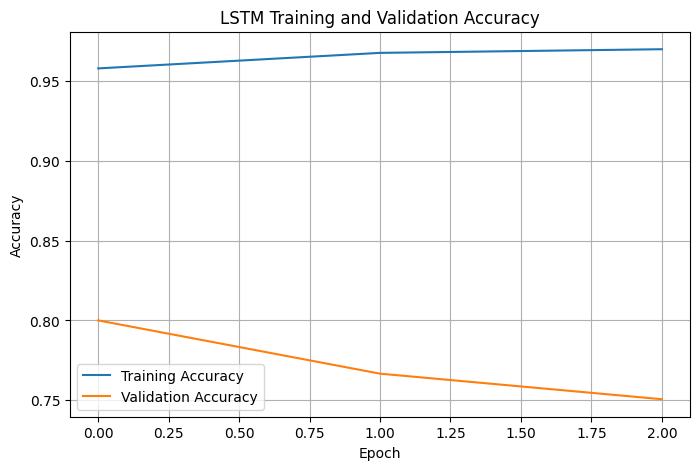

In [20]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()
